In [56]:
from pathlib import Path

import numpy as np
from langchain_community.vectorstores import FAISS
from langchain_community.vectorstores.utils import DistanceStrategy
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnableParallel, RunnablePassthrough
from langchain_ollama import OllamaEmbeddings


In [57]:
BASE_DIR = Path.cwd()
FAISS_DIR = BASE_DIR / "faiss_index"

EMBED_MODEL = "nomic-embed-text"
OLLAMA_BASE_URL = "http://localhost:11434"

TOP_K = 3

print("Index folder exists:", FAISS_DIR.exists())
print("Files:", [f.name for f in FAISS_DIR.iterdir()])


Index folder exists: True
Files: ['index.faiss', 'index.pkl']


In [58]:
embeddings = OllamaEmbeddings(model=EMBED_MODEL, base_url=OLLAMA_BASE_URL)

store = FAISS.load_local(
    str(FAISS_DIR),
    embeddings,
    allow_dangerous_deserialization=True,
    normalize_L2=True,
    distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT,
)

print("Vectors in index:", store.index.ntotal)
print("Dimensions      :", store.index.d)


Vectors in index: 20
Dimensions      : 768


c:\Users\ARTI\Desktop\Abhishek\RAG-Chatbot-2-FAISS\.venv\Lib\site-packages\langchain_community\vectorstores\faiss.py:233: UserWarning: Normalizing L2 is not applicable for metric type: DistanceStrategy.MAX_INNER_PRODUCT
  warnings.warn(


In [59]:
question = "What is chunking in RAG?"
print("User query:", question)


User query: What is chunking in RAG?


In [60]:
query_vector = embeddings.embed_query(question)

print("Dimensions     :", len(query_vector))
print("First 5 numbers:", query_vector[:5])
print("Vector length  :", np.linalg.norm(query_vector))


Dimensions     : 768
First 5 numbers: [0.07191207, 0.023175, -0.15679449, -0.1121638, 0.009952541]
Vector length  : 0.9999998551595798


In [61]:
# Pull every stored vector out of the FAISS index (already length 1)
all_vectors = store.index.reconstruct_n(0, store.index.ntotal)   # shape: (chunks, 768)
q = np.array(query_vector)                                        # shape: (768,)

# cosine similarity = dot(a, b) / (length(a) * length(b))
similarities = all_vectors @ q / (
    np.linalg.norm(all_vectors, axis=1) * np.linalg.norm(q)
)

ranking = np.argsort(similarities)[::-1]      # best chunk first


def chunk_at(row: int):
    """FAISS row number -> the chunk's Document, via the ID map and docstore."""
    return store.docstore.search(store.index_to_docstore_id[int(row)])


for rank, row in enumerate(ranking[:5], start=1):
    doc = chunk_at(row)
    preview = doc.page_content[:60].replace("\n", " ")
    print(f"#{rank}  cosine={similarities[row]:.3f}  chunk {doc.metadata['chunk_id']}: {preview}...")
    

#1  cosine=0.608  chunk 9:  A fallback when no relevant chunk is found ("I don't know"...
#2  cosine=0.594  chunk 7: RAG Notes (updated) Page 4 Step 3. Find relevant chunks   C...
#3  cosine=0.580  chunk 0: RAG Notes (updated) Page 1  RAG Notes (updated)...
#4  cosine=0.579  chunk 10: RAG Notes (updated) Page 5 More to try:   Semantic chunking...
#5  cosine=0.572  chunk 2:  Give the retrieved information to the LLM.   The LLM answ...


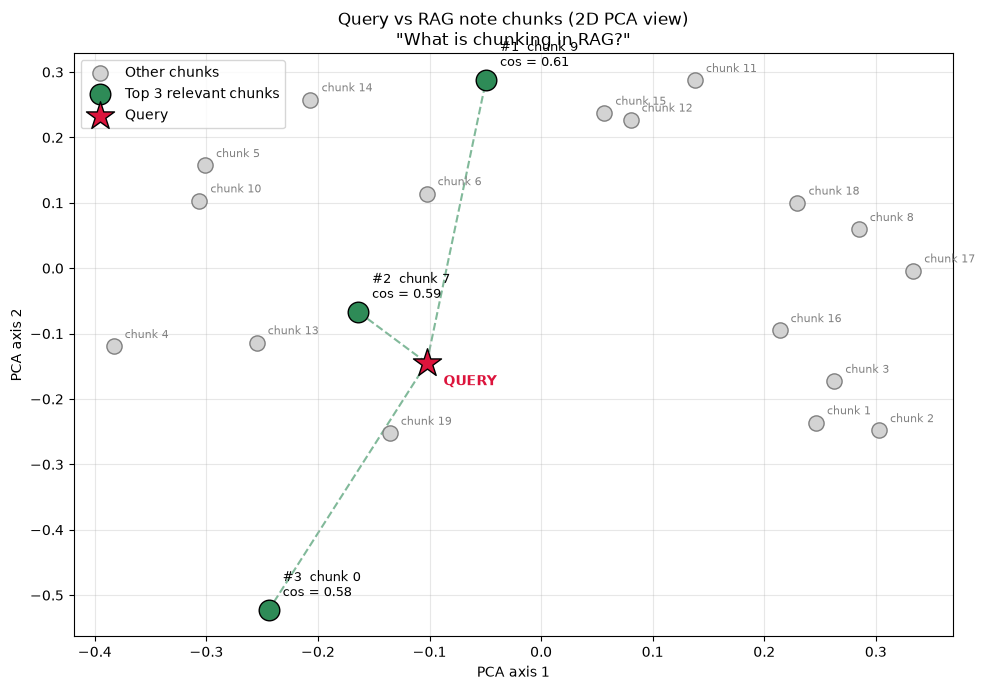

In [62]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Squash 768-dim vectors down to 2D (fit on the chunks, then project the query)
pca = PCA(n_components=2)
chunks_xy = pca.fit_transform(all_vectors)        # shape: (20, 2)
query_xy = pca.transform(q.reshape(1, -1))[0]     # shape: (2,)

# 2. Which chunks are the top results, and each chunk's id
top_idx = ranking[:TOP_K]
chunk_ids = [chunk_at(i).metadata["chunk_id"] for i in range(len(all_vectors))]

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 7))

# All chunks (grey)
ax.scatter(chunks_xy[:, 0], chunks_xy[:, 1], s=120, color="lightgrey",
           edgecolor="grey", label="Other chunks", zorder=2)

# Top-k chunks (green), with a dashed line to the query
for rank, idx in enumerate(top_idx, start=1):
    x, y = chunks_xy[idx]
    ax.scatter(x, y, s=220, color="seagreen", edgecolor="black", zorder=3,
               label=f"Top {TOP_K} relevant chunks" if rank == 1 else None)
    ax.plot([query_xy[0], x], [query_xy[1], y],
            linestyle="--", color="seagreen", alpha=0.6, zorder=1)
    ax.annotate(f"#{rank}  chunk {chunk_ids[idx]}\ncos = {similarities[idx]:.2f}",
                (x, y), textcoords="offset points", xytext=(10, 10), fontsize=9)

# The query (red star)
ax.scatter(query_xy[0], query_xy[1], s=450, marker="*", color="crimson",
           edgecolor="black", zorder=4, label="Query")
ax.annotate("QUERY", query_xy, textcoords="offset points",
            xytext=(12, -16), fontsize=10, fontweight="bold", color="crimson")

# Light labels for the remaining chunks
for idx in range(len(chunks_xy)):
    if idx not in top_idx:
        ax.annotate(f"chunk {chunk_ids[idx]}", chunks_xy[idx],
                    textcoords="offset points", xytext=(8, 6), fontsize=8, color="grey")

ax.set_title(f'Query vs RAG note chunks (2D PCA view)\n"{question}"')
ax.set_xlabel("PCA axis 1")
ax.set_ylabel("PCA axis 2")
ax.grid(alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.show()


In [63]:
results = store.similarity_search_with_score(question, k=TOP_K)

for doc, score in results:
    print(f"score={score:.3f} | chunk {doc.metadata['chunk_id']} | page {doc.metadata['page'] + 1}")

print("\nManual top 3 chunk IDs :", [chunk_at(r).metadata["chunk_id"] for r in ranking[:3]])
print("FAISS top 3 chunk IDs  :", [d.metadata["chunk_id"] for d, _ in results])


score=0.608 | chunk 9 | page 4
score=0.594 | chunk 7 | page 4
score=0.580 | chunk 0 | page 1

Manual top 3 chunk IDs : [9, 7, 0]
FAISS top 3 chunk IDs  : [9, 7, 0]


In [64]:
retriever = store.as_retriever(
    search_type="similarity",
    search_kwargs={"k": TOP_K},
)

top_docs = retriever.invoke(question)

for i, d in enumerate(top_docs, start=1):
    print(f"\n=== Relevant Chunk {i} | chunk_id {d.metadata['chunk_id']} | page {d.metadata['page'] + 1} ===")
    print(d.page_content)
    


=== Relevant Chunk 1 | chunk_id 9 | page 4 ===
 A fallback when no relevant chunk is found ("I don't know").
 
Text splitting
Types of text splitters
1. CharacterTextSplitter
  Splits on a single separator.
 2. RecursiveCharacterTextSplitter
  Tries a list of separators in order (paragraph → line → sentence → word).
  Best default.
 3. TokenTextSplitter
  Splits by token count.
 Important parameters:
  chunk_size
  chunk_overlap

=== Relevant Chunk 2 | chunk_id 7 | page 4 ===
RAG Notes (updated)
Page 4
Step 3. Find relevant chunks
  Compare the query vector with the document vectors in the vector DB.
  Take the top-k most similar chunks.
 Step 4. Combine
  Combine the query with the relevant chunks into one prompt (context + question).
 Settings to tune:
  k (number of chunks)
  Score threshold
  MMR (Maximal Marginal Relevance) for less repetitive chunks
  Metadata filters (by source, page, date)
 Better approach:
  Query rewriting
  Multi-query

=== Relevant Chunk 3 

In [65]:
def format_docs(docs) -> str:
    return "\n\n---\n\n".join(d.page_content for d in docs)


format_runnable = RunnableLambda(format_docs)

retrieval_chain = retriever | format_runnable

context_text = retrieval_chain.invoke(question)
print(context_text[:500])


 A fallback when no relevant chunk is found ("I don't know").
 
Text splitting
Types of text splitters
1. CharacterTextSplitter
  Splits on a single separator.
 2. RecursiveCharacterTextSplitter
  Tries a list of separators in order (paragraph → line → sentence → word).
  Best default.
 3. TokenTextSplitter
  Splits by token count.
 Important parameters:
  chunk_size
  chunk_overlap

---

RAG Notes (updated)
Page 4
Step 3. Find relevant chunks
  Compare the query vector with the document


In [66]:
setup = RunnableParallel(
    context=retriever | format_runnable,
    question=RunnablePassthrough(),
)

prepared = setup.invoke(question)

print("Keys    :", list(prepared.keys()))
print("question:", prepared["question"])
print("context (first 200 chars):", prepared["context"][:200])


Keys    : ['context', 'question']
question: What is chunking in RAG?
context (first 200 chars):  A fallback when no relevant chunk is found ("I don't know").
 
Text splitting
Types of text splitters
1. CharacterTextSplitter
  Splits on a single separator.
 2. RecursiveCharacterTextSplitter
  


In [67]:
SYSTEM_PROMPT = """You answer questions about RAG (Retrieval-Augmented Generation) using ONLY the context below.

Rules:
1. Answer ONLY what the question asks. Do not add background, extra tips or related topics.
2. The context may contain parts that are unrelated to the question. Ignore those parts completely.
3. Be short: 2 to 4 sentences. Use a short bullet list only if the question asks for steps, types or a comparison.
4. If the answer is not in the context, reply exactly: "I couldn't find that in the notes."

Context:
{context}"""

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", SYSTEM_PROMPT),
        ("human", "{question}"),
    ]
)

print("Placeholders the prompt needs:", prompt.input_variables)


Placeholders the prompt needs: ['context', 'question']


In [68]:
prompt_builder = setup | prompt

final_prompt = prompt_builder.invoke(question)
print(final_prompt.to_string())


System: You answer questions about RAG (Retrieval-Augmented Generation) using ONLY the context below.

Rules:
1. Answer ONLY what the question asks. Do not add background, extra tips or related topics.
2. The context may contain parts that are unrelated to the question. Ignore those parts completely.
3. Be short: 2 to 4 sentences. Use a short bullet list only if the question asks for steps, types or a comparison.
4. If the answer is not in the context, reply exactly: "I couldn't find that in the notes."

Context:
 A fallback when no relevant chunk is found ("I don't know").
 
Text splitting
Types of text splitters
1. CharacterTextSplitter
  Splits on a single separator.
 2. RecursiveCharacterTextSplitter
  Tries a list of separators in order (paragraph → line → sentence → word).
  Best default.
 3. TokenTextSplitter
  Splits by token count.
 Important parameters:
  chunk_size
  chunk_overlap

---

RAG Notes (updated)
Page 4
Step 3. Find relevant chunks
  Compare the query vecto

In [69]:
from langchain_ollama import ChatOllama


In [70]:
LLM_MODEL = "mistral"

llm = ChatOllama(
    model=LLM_MODEL,
    base_url=OLLAMA_BASE_URL,
    temperature=0,
)

print("LLM ready:", LLM_MODEL)


LLM ready: mistral


In [71]:
streaming_rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
)


In [72]:
{"context": retriever | format_docs, "question": RunnablePassthrough()}


{'context': VectorStoreRetriever(tags=['FAISS', 'OllamaEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x0000020D94DCDA30>, search_kwargs={'k': 3})
 | RunnableLambda(format_docs),
 'question': RunnablePassthrough()}

In [73]:
## The normal way (invoke)

question = "What is chunking in RAG?"

answer = streaming_rag_chain.invoke(question)

print("Answer:", answer.content)


Answer:  Chunking in RAG refers to the process of breaking down a large document into smaller, more manageable pieces or chunks, for efficient retrieval and generation of responses.


In [74]:
## The real-time way (stream)

question = "What is chunking in RAG?"

print("Answer: ", end="", flush=True)

for chunk in streaming_rag_chain.stream(question):
    print(chunk.content, end="", flush=True)

print()


Answer:  Chunking in RAG refers to the process of breaking down a large document into smaller, more manageable pieces or chunks, for efficient retrieval and generation of responses.


In [75]:
def stream_answer(question: str) -> None:
    print("Question:", question)
    print("Answer: ", end="", flush=True)

    for chunk in streaming_rag_chain.stream(question):
        print(chunk.content, end="", flush=True)

    print("\n" + "-" * 60)


stream_answer("What is chunking in RAG?")
stream_answer("Why do we use embeddings?")


Question: What is chunking in RAG?
Answer: 

 Chunking in RAG refers to the process of breaking down a large document into smaller, more manageable pieces or chunks, for efficient retrieval and generation of responses.
------------------------------------------------------------
Question: Why do we use embeddings?
Answer:  Embeddings are used in RAG (Retrieval-Augmented Generation) to convert text into numerical vectors. This process allows the model to compare and find similarities between different pieces of text, making it easier to match user queries with relevant document chunks. The vectors are then stored in a vector database like FAISS, Chroma, Pinecone, or DataStax (Astra DB).
------------------------------------------------------------


In [76]:
stream_answer("Who won the 2022 football World Cup?")


Question: Who won the 2022 football World Cup?
Answer:  I couldn't find that in the notes. The context does not provide information about the 2022 football World Cup winner.
------------------------------------------------------------


In [77]:
def stream_answer_with_sources(question: str) -> None:
    print("Question:", question)
    print("Answer: ", end="", flush=True)

    for chunk in streaming_rag_chain.stream(question):
        print(chunk.content, end="", flush=True)

    print("\n\nSources used:")
    for d in retriever.invoke(question):
        print(f"  - chunk {d.metadata['chunk_id']}, page {d.metadata['page'] + 1}")

    print("-" * 60)


stream_answer_with_sources("What is chunking in RAG?")


Question: What is chunking in RAG?
Answer: 

 Chunking in RAG refers to the process of breaking down a large document into smaller, more manageable pieces or chunks, for efficient retrieval and generation of responses.

Sources used:
  - chunk 9, page 4
  - chunk 7, page 4
  - chunk 0, page 1
------------------------------------------------------------
